In [2]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [3]:
class State(TypedDict):
    # Messages have the type "List". The add_messages function in the annotation defines how the state key should be updated.
    # In our case, Appends the list, rather than overwriting.
    messages: Annotated[list, add_messages]

graph = StateGraph(State)

In [4]:
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
from langchain.chat_models import init_chat_model
llm = init_chat_model("openrouter:meta-llama/llama-3.3-70b-instruct:free")

In [8]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [13]:
graph.add_node("llmchabot", chatbot)
graph.add_edge(START, "llmchabot")
graph.add_edge("llmchabot", END)
graph1 = graph.compile()

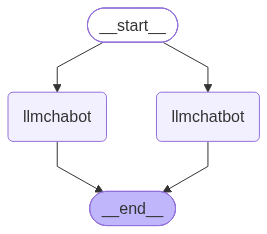

In [15]:
from IPython.display import Image,display

try:
    display(Image(graph1.get_graph().draw_mermaid_png()))
except:
    pass

In [ ]:
graph1.invoke("HI") # this will not work since we have defined a dict in our state
graph1.invoke({"messages":"Hi"})

In [ ]:
for event in graph.stream({"messages":"Hi"}):
    print(event) # we will get the node and its functionality details
    for value in event.values():
        print(value) # we will get the messages, that too the AI messages.
        print(value["messages"][-1].content)

## Chatbot with Tools

In [ ]:
from langchain_tavily import tavily_search

tool = tavily_search(max_results=2)
tool.invoke("What is AI")

In [17]:
def multiply(a:int, b:int)->int:
    """
    Multiply a and b
    args:
        a (int): First Integer
        b (int): Second Integer
    Returns:
        int: which is the answer or output integer from multiplication.
    """
    return a*b

In [20]:
tools = [tool, multiply]
llm.bind_tools(tools)
llm_with_tools = llm.bind_tools(tools)

NameError: name 'tool' is not defined

In [19]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

def llm_with_tool(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("llm_with_tool", llm_with_tool)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "llm_with_tool")
builder.add_conditional_edges(
    "llm_with_tool",
    tools_condition
)
builder.add_edge("tools", END)
graph2 = builder.compile()


NameError: name 'tools' is not defined

In [ ]:
from IPython.display import Image,display

try:
    display(Image(graph1.get_graph().draw_mermaid_png()))
except:
    pass

In [ ]:
response = graph.invoke({"messages": "What is the recent dollar pricee to inr"})

In [ ]:
for m in response["messages"]:
    m.pretty_print()